<img src="https://www.unad.edu.co/images/footer/logo-unad-acreditacion-min.png" width="780" height="140" align="right"/>

In [ ]:
import sys
from pathlib import Path
import random
import numpy as np
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
for _p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
    if (_p / "src" / "utils.py").exists():
        if str(_p) not in sys.path:
            sys.path.insert(0, str(_p))
        break
try:
    from src.utils import set_seed, plot_confusion_matrix
    set_seed(RANDOM_STATE)
    print(f"[setup] seed={RANDOM_STATE} OK")
except Exception as e:
    print("[setup] src.utils no disponible:", e)




<p style="text-align: center;"> Curso: Machine Learning</p>

<p style="text-align: center;"> Código Curso: 203008067 </p>

<p style="text-align: center;"> Grupo: 203008067_33 </p>

<p style="text-align: center;"> Fase 3 - Componente práctico - Algoritmos no supervisados</p>

<p style="text-align: center;">  Presentado por: Luis Angel Quezada Aguirre</p>

<p style="text-align: center;">  Tutor(a): Jorge Luis Quintero</p>

<p style="text-align: center;"> UNIVERSIDAD NACIONAL ABIERTA Y A DISTANCIA - UNAD </p>

# Importar librerías y datasets

In [1]:
## Configuración del environment para evitar warnings
import os
os.environ["OMP_NUM_THREADS"] = "1"


In [2]:

# Manipulación de datos
import pandas as pd
import numpy as np

# Carga de datos
from sklearn.datasets import fetch_openml

# Preprocesamiento
from sklearn.preprocessing import StandardScaler

# Modelos de clustering
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering

# Métricas de evaluación (no supervisada)
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

# Reducción de dimensionalidad (para visualización en 2D/3D)
from sklearn.decomposition import PCA

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

import os
os.environ["OMP_NUM_THREADS"] = "1"

print("Bibliotecas cargadas")



Bibliotecas cargadas


In [ ]:
dfr = fetch_openml(data_id=210, as_frame=True, parser="auto")  # data_id ya fija la version en OpenML
df = dfr.frame
df.head()



,seeded,season,NC,SC,NWC,TE
0,S,AUTUMN,1.65,1.80,3.33,1.69
1,U,AUTUMN,1.09,0.79,1.59,0.74
2,S,WINTER,2.39,0.36,2.06,0.81
3,U,WINTER,2.96,1.27,4.05,1.44
4,S,WINTER,4.16,2.16,6.00,2.48


Para el desarrollo de los modelos, se utiliza la base de datos ***Cloud (ID: 210)*** de OpenML, la cual contiene información sobre un experimento de siembra de nubes, que mide las precipitaciones de lluvia para ciertas zonas de Tasmania, entre los años de 1964 y 1971 (Rijn, 2014). El dataset contiene un tamaño de 108 entradas con 6 columnas, con variables númericas que miden la precipitación en pulgadas para ciertas zonas, en donde las variables *NC, SC y NWC* corresponden a las precipitaciones en las zonas de control norte, sur y noroeste, respectivamente; además, el dataset también contiene una varible binaria *seed* que da información sobre la siembra (S) o no (U) de las nubes, y la variable *season*, que señala la estación del año de la precipotación (Rijn, 2014).

In [ ]:
df.info()


# Preprocesamiento

In [4]:
# 1. Seleccionar variables
df_clust = df[['NC', 'SC', 'NWC', 'seeded']].copy()

# 2. Codificación robusta de 'seeded'
def estandarizar_seeded(valor):
    if pd.isna(valor):
        return np.nan
    v = str(valor).strip().upper()
    if v in ['S', 'SEEDED', 'SI', 'YES', '1']:
        return 1
    elif v in ['U', 'UNSEEDED', 'NO', '0']:
        return 0
    else:
        return np.nan

df_clust['seeded'] = df_clust['seeded'].apply(estandarizar_seeded)
df_clust = df_clust.dropna(subset=['seeded'])
df_clust['seeded'] = df_clust['seeded'].astype(int)

# 4. ESCALADO SOLO EN VARIABLES NUMÉRICAS CONTINUAS
numeric_cols = ['NC', 'SC', 'NWC']
scaler = StandardScaler()
df_clust[numeric_cols] = scaler.fit_transform(df_clust[numeric_cols])

# 5. Verificación final
assert set(df_clust['seeded'].unique()).issubset({0, 1}), "¡Error: 'seeded' no es 0/1!"
print("Preprocesamiento exitoso. 'seeded' permanece como 0/1 (no escalado).")

# Asignar a X_clust_scaled (ahora ya está preprocesado)
X_clust_scaled = df_clust


Preprocesamiento exitoso. 'seeded' permanece como 0/1 (no escalado).


In [ ]:
X_clust_scaled.head()


# Ejercicio 1: K-Means Clustering.

In [15]:
# 1. Seleccionar solo NC y SC del dataset preprocesado
X_2d = X_clust_scaled[['NC', 'SC']].values  # .values para obtener array numpy

# 2. Aplicar K-means
kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(X_2d)




C:\Users\qluis\AppData\Local\Temp\ipykernel_19988\4270179121.py:13: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "bo-" (-> color='b'). The keyword argument will take precedence.
  plt.plot(k_range, inertias, 'bo-', color='blue')


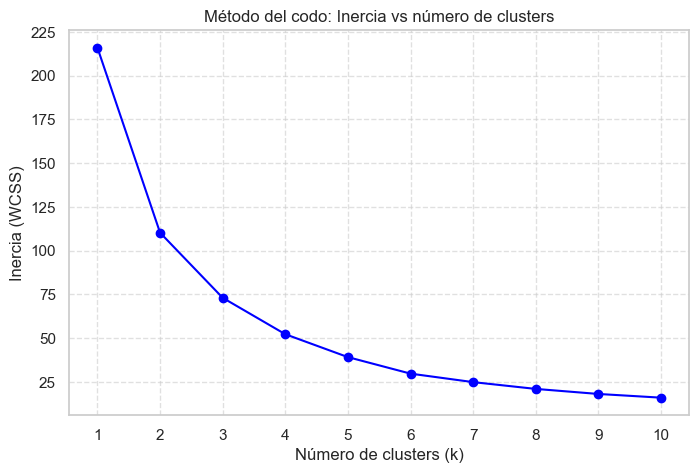

In [13]:
# Rango de k
k_range = range(1, 11)
inertias = []

# Calcular inercia para cada k
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_2d)
    inertias.append(kmeans.inertia_)

# Visualización
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, 'bo-', color='blue')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inercia (WCSS)')
plt.title('Método del codo: Inercia vs número de clusters')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(k_range)
plt.show()



C:\Users\qluis\AppData\Local\Temp\ipykernel_19988\1804764519.py:18: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "bo-" (-> color='b'). The keyword argument will take precedence.
  plt.plot(k_range, silhouette_scores, 'bo-', color='red')


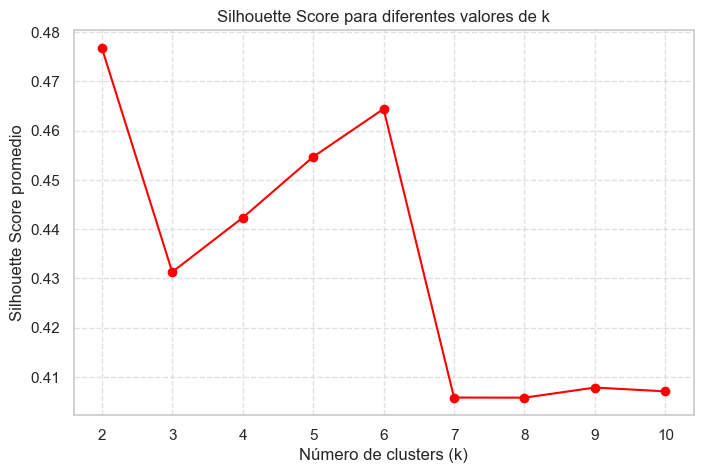

In [7]:
## Método de la silueta para K-means clustering
# Datos: solo NC y SC
X_2d = X_clust_scaled[['NC', 'SC']].values

# Rango de k a evaluar
k_range = range(2, 11)
silhouette_scores = []

# Calcular silhouette score para cada k
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_2d)
    silhouette_avg = silhouette_score(X_2d, cluster_labels)
    silhouette_scores.append(silhouette_avg)

# --- Gráfico 1: Silhouette Score vs k ---
plt.figure(figsize=(8, 5))
plt.plot(k_range, silhouette_scores, 'bo-', color='red')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette Score promedio')
plt.title('Silhouette Score para diferentes valores de k')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(k_range)
plt.show()


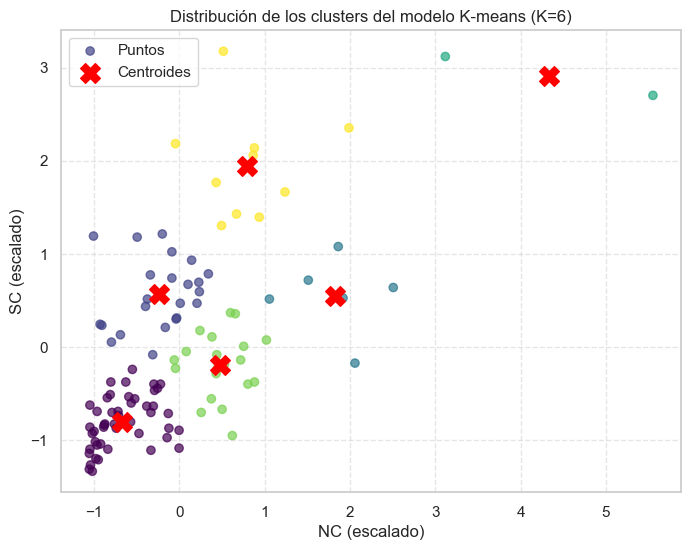

In [16]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_kmeans, cmap='viridis', alpha=0.7, label='Puntos')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            c='red', marker='X', s=200, label='Centroides')
plt.title('Distribución de los clusters del modelo K-means (K=6)')
plt.xlabel('NC (escalado)')
plt.ylabel('SC (escalado)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


In [9]:
X_3d = X_clust_scaled[['NC', 'SC', 'NWC']].values  # .values para obtener array numpy

# 2. Aplicar K-means
kmeans3 = KMeans(n_clusters=6, random_state=42, n_init=10)
y_kmeans3 = kmeans3.fit_predict(X_3d)



C:\Users\qluis\AppData\Local\Temp\ipykernel_19988\2017476824.py:12: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "bo-" (-> color='b'). The keyword argument will take precedence.
  plt.plot(k_range, inertias, 'bo-', color='blue')


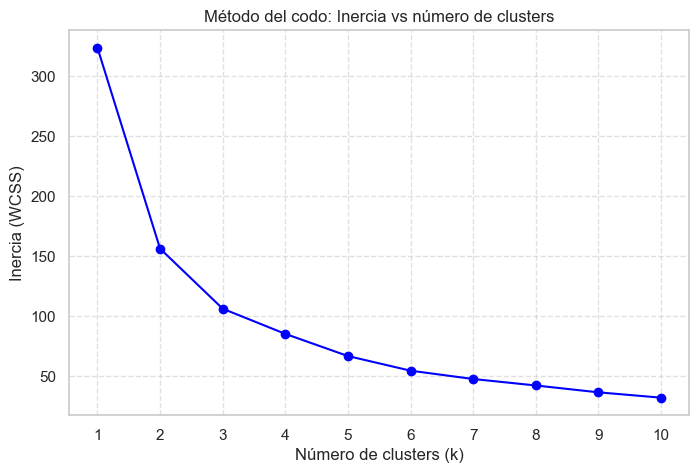

In [10]:
k_range = range(1, 11)
inertias = []

# Calcular inercia para cada k
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_3d)
    inertias.append(kmeans.inertia_)

# Visualización
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, 'bo-', color='blue')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inercia (WCSS)')
plt.title('Método del codo: Inercia vs número de clusters')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(k_range)
plt.show()


C:\Users\qluis\AppData\Local\Temp\ipykernel_19988\1810676855.py:13: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "bo-" (-> color='b'). The keyword argument will take precedence.
  plt.plot(k_range, silhouette_scores, 'bo-', color='red')


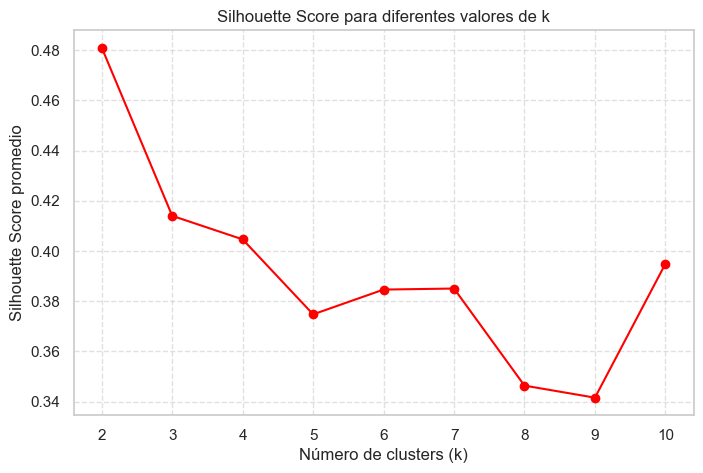

In [11]:
k_range = range(2, 11)
silhouette_scores = []

# Calcular silhouette score para cada k
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_3d)
    silhouette_avg = silhouette_score(X_3d, cluster_labels)
    silhouette_scores.append(silhouette_avg)

# --- Gráfico 1: Silhouette Score vs k ---
plt.figure(figsize=(8, 5))
plt.plot(k_range, silhouette_scores, 'bo-', color='red')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette Score promedio')
plt.title('Silhouette Score para diferentes valores de k')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(k_range)
plt.show()


## Interpretación

Inicialmente, se puso un número aleatorio como valor K para la cantidad de cluster. Posteriormente, gracias a la iteración y evaluación a través del método del codo y la silueta, se encuentra que el mejor valor para K es 6, debido a su buen puntaje tanto en Inercia como . Se señala que aumentar la cantidad de variables disminuyó la calidad del modelo y sus clusters; también se señala que se presentan 5 grupos uniformes, y un sexto grupo cuyos valores son atípicos (outliers)

# Ejercicio 2: DBSCAN

In [ ]:

min_samples = 4

# Calcular la distancia al min_samples-ésimo vecino más cercano (k = min_samples)
nbrs = NearestNeighbors(n_neighbors=min_samples).fit(X_3d)
distances, indices = nbrs.kneighbors(X_3d)

# Ordenar distancias del min_samples-ésimo vecino (índice -1) en orden descendente
k_distances = distances[:, -1]
k_distances_sorted = np.sort(k_distances)[::-1]

# Visualizar
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(k_distances_sorted) + 1), k_distances_sorted, color='blue')
plt.xlabel('Puntos ordenados por distancia al 4º vecino')
plt.ylabel('Distancia al 4º vecino más cercano')
plt.title('Gráfico de k-distances para selección de épsilon')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [ ]:
# -------------------------------------------------
# DBSCAN – Paso 2: Entrenamiento y análisis
# -------------------------------------------------
from sklearn.cluster import DBSCAN

# AJUSTA este valor según el gráfico anterior
eps = 0.7  # <-- MODIFICA ESTE VALOR BASADO EN TU GRÁFICA

# Entrenar DBSCAN
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
y_dbscan = dbscan.fit_predict(X_3d)

# Resultados
n_clusters = len(set(y_dbscan)) - (1 if -1 in y_dbscan else 0)
n_noise = list(y_dbscan).count(-1)

print(f"🎯 Parámetros usados: eps = {eps}, min_samples = {min_samples}")
print(f"🔢 Número de clusters: {n_clusters}")
print(f"⚠️  Puntos clasificados como ruido: {n_noise} ({100 * n_noise / len(y_dbscan):.1f}%)")

# Añadir etiquetas al DataFrame para análisis
df_dbscan = X_clust_scaled[['NC', 'SC', 'NWC']].copy()
df_dbscan['cluster'] = y_dbscan

# Mostrar resumen estadístico por cluster
print("\n=== Perfil de cada cluster (media de variables originales) ===")
cluster_summary = df_dbscan.groupby('cluster').mean()
display(cluster_summary.round(3))


In [ ]:
eps_values = [0.6, 0.7, 0.8]
for eps in eps_values:
    dbscan = DBSCAN(eps=eps, min_samples=4)
    labels = dbscan.fit_predict(X_3d)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    print(f"eps={eps}: Clusters={n_clusters}, Ruido={n_noise} ({100*n_noise/len(labels):.1f}%)")


In [ ]:
# -------------------------------------------------
# VISUALIZACIÓN 3D DE DBSCAN – NC, SC, NWC
# -------------------------------------------------
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Asegúrate de tener las etiquetas de DBSCAN (y_dbscan) y los datos (X_3d)
# Si ya ejecutaste DBSCAN, debería existir y_dbscan
# Si no, vuelve a entrenar con tu mejor eps (ej. eps=0.8)

from sklearn.cluster import DBSCAN
X_3d = X_clust_scaled[['NC', 'SC', 'NWC']].values
dbscan = DBSCAN(eps=0.8, min_samples=4)
y_dbscan = dbscan.fit_predict(X_3d)

# Crear gráfico 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Colores: ruido = gris, clusters = colores distintos
unique_labels = set(y_dbscan)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels) - (-1 in unique_labels)))

for k in unique_labels:
    if k == -1:
        # Ruido
        col = [0.6, 0.6, 0.6, 0.6]  # gris semitransparente
        label = 'Ruido'
    else:
        col = colors[k]
        label = f'Cluster {k}'
    
    class_member_mask = (y_dbscan == k)
    ax.scatter(X_3d[class_member_mask, 0], 
               X_3d[class_member_mask, 1], 
               X_3d[class_member_mask, 2],
               c=[col], label=label, alpha=0.7, s=50)

ax.set_xlabel('NC (escalado)')
ax.set_ylabel('SC (escalado)')
ax.set_zlabel('NWC (escalado)')
ax.set_title('DBSCAN – Visualización 3D (NC, SC, NWC)')
ax.legend()
plt.show()

# Mostrar resumen
n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
n_noise = list(y_dbscan).count(-1)
print(f"Clusters: {n_clusters} | Puntos de ruido: {n_noise}")


## Interpretación

El gráfico, a través del método de la situela, permitió encontrar el mejor valor para epsilon. Sin embargo, el algoritmo DSBCAN muestra solo un cluster, lo cual tiene sentido en términos de la finalidad y diseño del data set; el experimento de siembra de nubes en Tasmania fue realizado en un entorno controlado, por lo que no es de extrañarse que las variables de control elegidas conformen un solo cluster.

# Ejercicio 3: Agglomerative Clustering.

In [ ]:
# -------------------------------------------------
# MODELO FINAL: AGGLOMERATIVE CLUSTERING
# -------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

# 1. Seleccionar las 3 variables numéricas (ya escaladas)
X_final = X_clust_scaled[['NC', 'SC', 'NWC']].values
df_final = X_clust_scaled[['NC', 'SC', 'NWC']].copy()

# 2. DENDROGRAMA PARA SELECCIÓN DE k
print("=== Paso 1: Dendrograma para elegir k ===")
linkage_matrix = linkage(X_final, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(linkage_matrix, truncate_mode='level', p=5)
plt.title('Dendrograma – Agglomerative Clustering (método Ward)')
plt.xlabel('Clusters o puntos')
plt.ylabel('Distancia (inercia)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 3. Ajustar k según el dendrograma (ej. k=3)
k_optimo = 3  # 👈 AJUSTA ESTE VALOR SEGÚN TU INTERPRETACIÓN DEL DENDROGRAMA

# 4. ENTRENAR MODELO FINAL
print(f"\n=== Paso 2: Entrenando modelo con k = {k_optimo} ===")
agg_model = AgglomerativeClustering(n_clusters=k_optimo, linkage='ward')
y_agg = agg_model.fit_predict(X_final)

# Añadir clusters al DataFrame
df_final['cluster'] = y_agg

# 5. PERFIL DE CLUSTERS
print("\n=== Paso 3: Perfil de cada cluster (valores escalados) ===")
perfil = df_final.groupby('cluster').mean()
display(perfil.round(3))

# Interpretación cualitativa
print("\n=== Interpretación en contexto meteorológico ===")
for cluster_id in perfil.index:
    row = perfil.loc[cluster_id]
    print(f"\n• Cluster {cluster_id}:")
    # NC
    if row['NC'] > 0.5:
        nc = "ALTA precipitación en el norte"
    elif row['NC'] < -0.5:
        nc = "BAJA precipitación en el norte"
    else:
        nc = "precipitación PROMEDIO en el norte"
    # SC
    if row['SC'] > 0.5:
        sc = "ALTA en el sur"
    elif row['SC'] < -0.5:
        sc = "BAJA en el sur"
    else:
        sc = "PROMEDIO en el sur"
    # NWC
    if row['NWC'] > 0.5:
        nwc = "ALTA en el noroeste"
    elif row['NWC'] < -0.5:
        nwc = "BAJA en el noroeste"
    else:
        nwc = "PROMEDIO en el noroeste"
    print(f"  → {nc}, {sc}, {nwc}.")

# 6. VISUALIZACIÓN EN PARES
print("\n=== Paso 4: Visualización en 2D ===")
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
pairs = [('NC', 'SC'), ('NC', 'NWC'), ('SC', 'NWC')]
for i, (x, y) in enumerate(pairs):
    axes[i].scatter(df_final[x], df_final[y], c=y_agg, cmap='tab10', alpha=0.7, s=50)
    axes[i].set_xlabel(x)
    axes[i].set_ylabel(y)
    axes[i].set_title(f'{x} vs {y}')
    axes[i].grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 7. Resumen final
n_clusters = len(np.unique(y_agg))
print(f"\n Modelo final entrenado con {n_clusters} clusters.")
print("Los clusters reflejan regímenes climáticos distintos en el experimento de Tasmania.")


## Interpretación

Como interpetación final, debo señalar una anotación que aplica para todos los modelos. En este caso, no se pudieron usar más variables, debido a la ausencia de otras variables numéricas que no interfieran con el modelo. Debemos recordar que el dataset cuenta con una variable objetivo (TE), por lo que su uso para modelos no supervisados (y por ende con data no etiquetada) no es el mejor caso de uso para este. Por ende, se recomienda, en ejercicios posteriores, especificar una base de datos especializada para estos modelos. 

# REFERENCIAS

Rijn, J. (2014). Cloud. En *OpenML*. https://www.openml.org/search?type=data&status=active&id=210

## MEJORA GITHUB-READY — tabla comparativa final KMeans vs DBSCAN vs Agglomerative


In [ ]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
res = []
km6 = KMeans(n_clusters=6, random_state=42, n_init=10).fit_predict(X_3d)
res.append(('KMeans k=6', silhouette_score(X_3d, km6), calinski_harabasz_score(X_3d, km6), davies_bouldin_score(X_3d, km6)))
db = DBSCAN(eps=0.7, min_samples=4).fit_predict(X_3d)
mask = db != -1
if mask.sum() > 10 and len(set(db[mask])) > 1:
    res.append(('DBSCAN eps=0.7', silhouette_score(X_3d[mask], db[mask]), calinski_harabasz_score(X_3d[mask], db[mask]), davies_bouldin_score(X_3d[mask], db[mask])))
ag = AgglomerativeClustering(n_clusters=6).fit_predict(X_3d)
res.append(('Agglo k=6', silhouette_score(X_3d, ag), calinski_harabasz_score(X_3d, ag), davies_bouldin_score(X_3d, ag)))
print(pd.DataFrame(res, columns=['Modelo', 'silhouette', 'calinski', 'davies']).round(3).to_string(index=False))
xy = PCA(n_components=2, random_state=42).fit_transform(X_3d)
plt.figure(); plt.scatter(xy[:, 0], xy[:, 1], c=km6, alpha=0.5); plt.title('PCA 2D — KMeans (MEJORA)'); plt.show()
print('Conclusion MEJORA: elegir ganador por silhouette/davies, no solo visual; reportar ruido DBSCAN.')

